# Reconocimiento de objetos y ángulo con ML clásico (COIL-100)

Notebook reproducible de punta a punta: datos → análisis exploratorio → protocolos A-D → comparación con baseline y
referencia moderna → análisis de errores → robustez → exportación del artefacto. La lógica vive en `src/vision/`;
el notebook la llama y muestra los resultados. El barrido completo está registrado en MLflow (`mlruns/mlflow.db`) y
resumido en `eval/vision_summary.csv`. Con `RERUN_SWEEP = False` el notebook lee esos resultados en lugar de repetir
el barrido (unos 60 minutos en CPU).

In [1]:
import os, sys, json, hashlib
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RERUN_SWEEP = False
SEED = 42

## 1. Datos: descarga, verificación y versión

In [2]:
import subprocess
zip_path = Path("../datos_coil100/coil-100.zip")
args = [sys.executable, "data/download.py", "--out", "data/raw"] + (["--zip", str(zip_path)] if zip_path.exists() else [])
print(subprocess.run(args, capture_output=True, text=True).stdout)
from src.vision.data import load_index, load_images
from src.vision.sweep import DATA_SHA, load_all
index, images, feats = load_all()
print("SHA-256 del ZIP oficial:", DATA_SHA)
print(index.shape, "objetos:", index.obj_id.nunique(), "vistas por objeto:", index.groupby("obj_id").size().unique())

7200 imÃ¡genes extraÃ­das en data\raw (SHA-256 fcb4b8b01c0778f416d8d7a09f45082c4f7075cc74743dcddd5c44307bd4afe7)



SHA-256 del ZIP oficial: fcb4b8b01c0778f416d8d7a09f45082c4f7075cc74743dcddd5c44307bd4afe7
(7200, 3) objetos: 100 vistas por objeto: [72]


## 2. Análisis exploratorio

COIL-100 tiene 7.200 imágenes RGB de 128×128: 100 objetos y 72 vistas por objeto, una cada 5°. El objeto gira sobre una
plataforma (eje vertical): la rotación es **fuera del plano** de la imagen, así que el ángulo no se puede obtener girando
la foto; hay que aprenderlo por objeto. El fondo es negro, la luz controlada y la cámara está a una sola elevación.

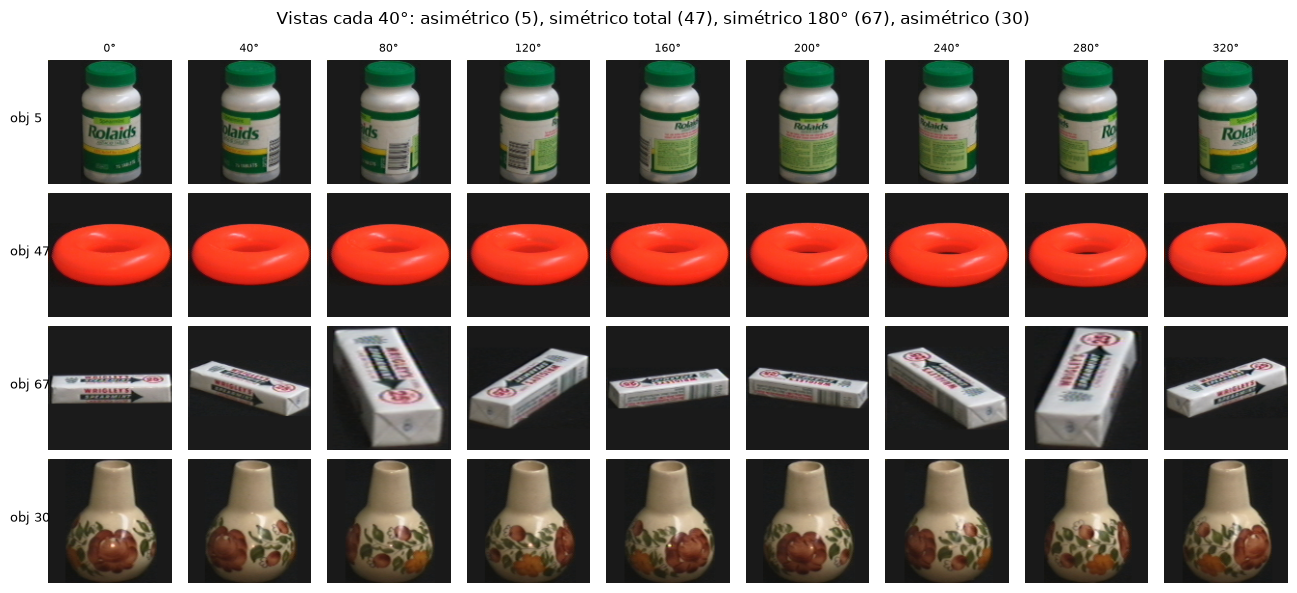

In [3]:
fig, axes = plt.subplots(4, 9, figsize=(13, 6))
for r, obj in enumerate([5, 47, 67, 30]):
    for c, ang in enumerate(range(0, 360, 40)):
        axes[r, c].imshow(images[(index.obj_id == obj) & (index.angle == ang)][0]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"{ang}°", fontsize=8)
    axes[r, 0].text(-40, 64, f"obj {obj}", fontsize=9)
plt.suptitle("Vistas cada 40°: asimétrico (5), simétrico total (47), simétrico 180° (67), asimétrico (30)"); plt.tight_layout(); plt.show()

Fracción de píxeles de objeto: media 0.99, p1 0.94, p99 1.00


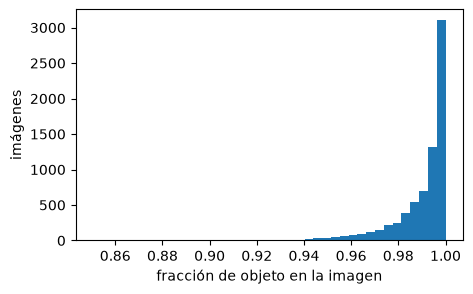

In [4]:
fg = (images.max(axis=3) > 20).mean(axis=(1, 2))
print("Fracción de píxeles de objeto: media %.2f, p1 %.2f, p99 %.2f" % (fg.mean(), np.percentile(fg, 1), np.percentile(fg, 99)))
plt.figure(figsize=(5, 3)); plt.hist(fg, bins=40); plt.xlabel("fracción de objeto en la imagen"); plt.ylabel("imágenes"); plt.show()

### Simetría

Para cada objeto se mide cuánto cambia (distancia en el espacio de ángulo) al girarlo 90° y 180°, comparado con el
objeto mediano del catálogo. Simétrico total: girarlo 90° le cambia menos del 30 % de lo que cambia el objeto mediano.
Simétrico de 180°: girarlo 180° le cambia menos del 40 % de lo que le cambia girarlo 90°.

In [5]:
from src.vision.model import ModelConfig, VisionModel
full = VisionModel(ModelConfig(classifier="knn", calibrate=False)).fit(None, index.obj_id, index.angle, index.path, precomputed=feats)
sym = pd.Series(full.symmetry)
print(sym.value_counts().rename({360: "asimétrico", 180: "simétrico 180°", 0: "simétrico total"}))
print("simétricos totales:", sorted(sym[sym == 0].index.tolist())); print("simétricos 180°:", sorted(sym[sym == 180].index.tolist()))

asimétrico         76
simétrico 180°     16
simétrico total     8
Name: count, dtype: int64
simétricos totales: [25, 34, 35, 47, 50, 56, 94, 95]
simétricos 180°: [1, 12, 22, 31, 33, 39, 51, 55, 65, 67, 79, 84, 88, 90, 91, 98]


### Qué condiciona el diseño y en qué difiere de una planta

| Propiedad de COIL-100 | Consecuencia en el diseño | Planta real |
|---|---|---|
| Rotación fuera del plano | Ángulo aprendido por objeto (vecinos entre sus vistas) | Igual si el objeto gira sobre la cinta |
| Ángulo circular | Error con distancia circular; media y dispersión circulares | Igual |
| Objetos simétricos | Modo de ángulo `exact` / `mod180` / `any` y métrica con simetría | Igual: la pinza no distingue giros equivalentes |
| Fondo negro, luz fija, objeto centrado | Control de calidad por desenfoque, exposición y fracción de objeto | Fondo y luz variables, varios objetos: haría falta segmentación |
| Una elevación de cámara | Sin variación de inclinación | Objetos volcados o apoyados distinto |
| Vistas cada 5° | Con datos cada 10° (A) el vecino correcto queda a ≤ 5° | Alta de productos: pedir vistas cada 10-15° |

## 3. Protocolos y validación sin tocar la prueba

| Protocolo | Entrenamiento | Prueba | Validación interna (solo vistas de entrenamiento) |
|---|---|---|---|
| A | 0°, 10°, 20°… | 5°, 15°, 25°… | entrenar en múltiplos de 20°, validar en 10°, 30°… |
| B | todo menos un arco de 60° por objeto | el arco | otro arco contiguo de 60° dentro de lo visto |
| C | una vista cada 30° | las 60 restantes | dejar una vista fuera (12 folds) |
| D | 90 objetos (vistas cada 10°) | vistas a 5° de los 90 + 10 objetos completos | 10 de los conocidos como desconocidos simulados |

Los umbrales de la política (puerta de desconocidos y puntuación de agarre) se eligen **solo** en validación con un
riesgo de agarre erróneo ≤ 1 %; la prueba se evalúa una vez. Agarre correcto = clase correcta y error angular
(con simetría) ≤ 10°, la tolerancia del robot.

In [6]:
from src.vision.protocols import make_split, save_splits
splits = {p: make_split(index, p) for p in "ABCD"}
for p, s in splits.items(): print(p, "train", len(s.train_idx), "test", len(s.test_idx), {k: (v if k != "arc_start" else "...") for k, v in s.meta.items()})

A train 3600 test 3600 {}
B train 6000 test 1200 {'arc_start': '...'}
C train 1200 test 6000 {}
D train 3240 test 3960 {'unknown_objs': [9, 10, 20, 42, 61, 69, 72, 83, 95, 97]}


## 4. Barrido: 4 clasificadores × 3 combinaciones de características, baseline y ResNet-50

In [7]:
if RERUN_SWEEP:
    Path("eval/vision_summary.csv").unlink(missing_ok=True)
    subprocess.run([sys.executable, "-m", "src.vision.sweep", "--stage", "grid"], check=True)
    subprocess.run([sys.executable, "-m", "src.vision.sweep", "--stage", "angle"], check=True)
summary = pd.read_csv("eval/vision_summary.csv")
cols = ["protocol", "family", "name", "val_coverage", "val_wrong_pick_rate", "test_class_acc", "test_angle_within_tol_sym",
        "test_angle_median_err_sym", "test_ece", "test_coverage", "test_wrong_pick_rate", "latency_ms"]
grid = summary[summary.family != "angle"][cols]
grid.round(4)

,protocol,family,name,val_coverage,val_wrong_pick_rate,test_class_acc,test_angle_within_tol_sym,test_angle_median_err_sym,test_ece,test_coverage,test_wrong_pick_rate,latency_ms
0,A,baseline,1nn-pixels,0.0783,0.0000,0.9664,0.9756,5.0000,0.0735,0.0994,0.0000,5.7316
1,A,classical,knn-color+hog,0.0800,0.0000,0.9864,0.9896,0.3217,0.0335,0.1447,0.0000,1.5870
2,A,classical,knn-color+hog+lbp,0.0833,0.0000,0.9867,0.9896,0.3212,0.0339,0.3156,0.0026,1.4121
3,A,classical,knn-color+lbp+pixels,0.0900,0.0123,0.9892,0.9896,0.3217,0.0198,0.4794,0.0017,1.4816
4,A,classical,svm-color+hog,0.0844,0.0066,0.9986,0.9897,0.3242,0.0011,0.4656,0.0036,2.2683
5,A,classical,svm-color+hog+lbp,0.0900,0.0123,0.9994,0.9897,0.3246,0.0006,0.4989,0.0033,2.4216
6,A,classical,svm-color+lbp+pixels,0.0800,0.0000,0.9972,0.9897,0.3244,0.0013,0.2744,0.0000,2.6630
7,A,classical,rf-color+hog,0.0856,0.0065,0.9911,0.9896,0.3219,0.0131,0.3658,0.0030,1.8439
8,A,classical,rf-color+hog+lbp,0.0856,0.0065,0.9925,0.9896,0.3225,0.0109,0.3997,0.0028,1.6653
9,A,classical,rf-color+lbp+pixels,0.0800,0.0000,0.9950,0.9897,0.3229,0.0053,0.4389,0.0013,1.8733


In [8]:
mean_score = summary[summary.family == "classical"].groupby("name")["selection_score"].mean().sort_values(ascending=False)
print("Selección en validación (media de A-D de cobertura − 10 × agarre erróneo):"); print(mean_score.round(4).head(6))
best_name = mean_score.index[0]; print("Mejor clásico:", best_name)

Selección en validación (media de A-D de cobertura − 10 × agarre erróneo):
name
logreg-color+lbp+pixels    0.0607
logreg-color+hog           0.0279
rf-color+hog               0.0118
logreg-color+hog+lbp       0.0013
rf-color+lbp+pixels       -0.0057
knn-color+hog             -0.0071
Name: selection_score, dtype: float64
Mejor clásico: logreg-color+lbp+pixels


### Comparación obligatoria: baseline, mejor clásico y referencia moderna

In [9]:
ref = summary[summary.family == "reference"].sort_values("test_class_acc").groupby("protocol").tail(1)
rows = []
for p in "ABCD":
    for fam, name in [("baseline", "1nn-pixels"), ("classical", best_name)]:
        r = summary[(summary.protocol == p) & (summary.family == fam) & (summary.name == name)].iloc[0]; rows.append(r)
    rows.append(ref[ref.protocol == p].iloc[0])
cmp = pd.DataFrame(rows)[["protocol", "family", "name", "test_class_acc", "test_angle_within_tol_sym", "test_coverage", "test_wrong_pick_rate", "latency_ms"]]
cmp.round(4)

,protocol,family,name,test_class_acc,test_angle_within_tol_sym,test_coverage,test_wrong_pick_rate,latency_ms
0,A,baseline,1nn-pixels,0.9664,0.9756,0.0994,0.0000,5.7316
12,A,classical,logreg-color+lbp+pixels,0.9992,0.9897,0.5072,0.0011,1.4017
14,A,reference,resnet50-logreg,0.9997,0.8094,0.0642,0.0216,1.5512
15,B,baseline,1nn-pixels,0.7842,0.4718,0.0950,0.0000,5.6008
27,B,classical,logreg-color+lbp+pixels,0.9600,0.3776,0.0975,0.0171,2.1784
29,B,reference,resnet50-logreg,0.9875,0.1342,0.0300,0.0000,2.0360
30,C,baseline,1nn-pixels,0.8330,0.7283,0.0662,0.2242,5.3341
42,C,classical,logreg-color+lbp+pixels,0.9882,0.7634,0.2018,0.0941,1.6563
44,C,reference,resnet50-logreg,0.9993,0.4123,0.0400,0.0000,1.5421
45,D,baseline,1nn-pixels,0.9673,0.9757,0.0167,0.0000,5.5582


In [10]:
import time, joblib, io
from src.vision.reference_cnn import embed
t0 = time.perf_counter(); _ = embed(images[:64]); cnn_ms = (time.perf_counter() - t0) * 1000 / 64
print(f"ResNet-50 en CPU: {cnn_ms:.1f} ms por imagen (más la extracción de características clásicas, que no hace falta)")
buf = io.BytesIO(); joblib.dump(full, buf); print(f"Tamaño de un modelo clásico serializado: {buf.tell()/1e6:.1f} MB; ResNet-50: ~100 MB de pesos")

ResNet-50 en CPU: 137.2 ms por imagen (más la extracción de características clásicas, que no hace falta)
Tamaño de un modelo clásico serializado: 14.1 MB; ResNet-50: ~100 MB de pesos


## 5. Ángulo: vecinos frente a kernel ridge

In [11]:
ang = summary[summary.family == "angle"]
ang.pivot_table(index="name", columns="protocol", values=["test_angle_within_tol_sym", "val_coverage"]).round(3) if len(ang) else "sin etapa de ángulo"

test_angle_within_tol_sym                      val_coverage                     
protocol                                A      B      C      D            A      B      C      D
name                                                                                            
kernel_ridge-k3                     0.991  0.479  0.833  0.989        0.249  0.122  0.203  0.071
knn-k1                              0.994  0.465  0.734  0.994        0.084  0.102  0.235  0.070
knn-k5                              0.900  0.286  0.407  0.899        0.131  0.080  0.083  0.088

## 6. Confianza: calibración, riesgo-cobertura y rechazo (mejor clásico)

Mejor configuración clásica (media de validación en A-D): logreg-color+lbp+pixels 0.0607


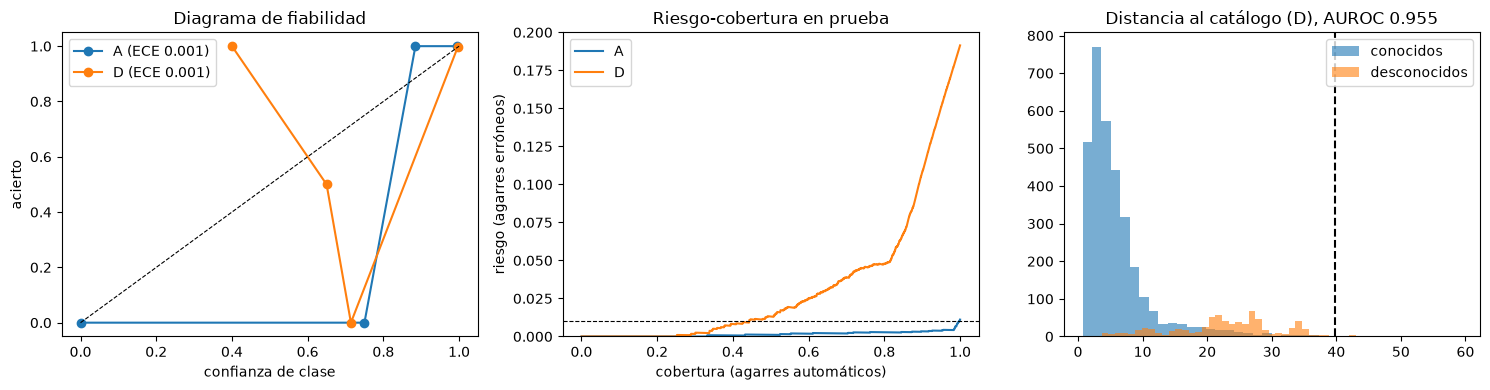

In [12]:
from src.vision.experiments import run_protocol, accepted_mask, pick_score
from src.vision.metrics import risk_coverage, ece, auroc
from src.vision.sweep import best_classical
cfg = best_classical()
res = {p: run_protocol(p, cfg, index, feats, DATA_SHA, mlflow_uri=None) for p in "AD"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for p, r in res.items():
    t = r["test"]; known = t[t.known]
    bins = np.linspace(0, 1, 11); idx = np.digitize(known.prob, bins) - 1
    xs = [known.prob[idx == b].mean() for b in range(10) if (idx == b).any()]; ys = [known.cls_ok[idx == b].mean() for b in range(10) if (idx == b).any()]
    ax[0].plot(xs, ys, "o-", label=f"{p} (ECE {ece(known.prob, known.cls_ok):.3f})")
    good = (t.cls_ok & (t.err_sym <= 10)).to_numpy(); cov, risk = risk_coverage(pick_score(t, r["thresholds"]), good)
    ax[1].plot(cov, risk, label=p)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlabel("confianza de clase"); ax[0].set_ylabel("acierto"); ax[0].set_title("Diagrama de fiabilidad"); ax[0].legend()
ax[1].axhline(0.01, color="k", ls="--", lw=0.8); ax[1].set_xlabel("cobertura (agarres automáticos)"); ax[1].set_ylabel("riesgo (agarres erróneos)"); ax[1].set_ylim(0, 0.2); ax[1].set_title("Riesgo-cobertura en prueba"); ax[1].legend()
d = res["D"]["test"]; ax[2].hist(d[d.known].ood, bins=40, alpha=.6, label="conocidos"); ax[2].hist(d[~d.known].ood, bins=40, alpha=.6, label="desconocidos")
ax[2].axvline(res["D"]["thresholds"]["max_ood"], color="k", ls="--"); ax[2].set_title(f"Distancia al catálogo (D), AUROC {auroc(-d[d.known].ood, -d[~d.known].ood):.3f}"); ax[2].legend()
plt.tight_layout(); plt.savefig("docs/img/confianza.png", dpi=110); plt.show()

La confianza es una base válida para decidir si (1) está calibrada (ECE bajo), (2) al exigir más confianza el error de
lo aceptado baja (curva riesgo-cobertura decreciente) y (3) separa conocidos de desconocidos (AUROC alto). La política
usa la puntuación de agarre con el umbral elegido en validación.

## 7. Análisis de errores

Pares de clase más confundidos (A):
true_obj  pred_obj
39        21          1
44        21          1
          57          1
dtype: int64
Objetos con mayor error angular mediano (A, con simetría):
true_obj
66    5.0
64    1.0
11    1.0
99    0.7
98    0.7
79    0.7
84    0.7
10    0.7
Name: err_sym, dtype: float64


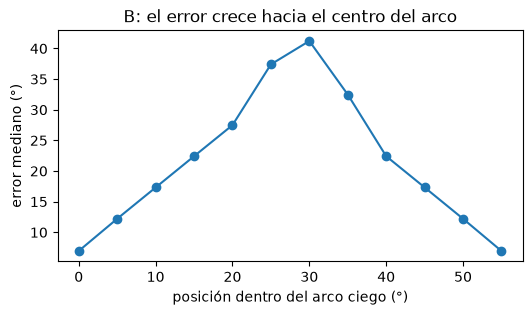

In [13]:
t = res["A"]["test"]; known = t[t.known]
conf = known[~known.cls_ok].groupby(["true_obj", "pred_obj"]).size().sort_values(ascending=False).head(8)
print("Pares de clase más confundidos (A):"); print(conf)
err_obj = known[known.cls_ok].groupby("true_obj").err_sym.median().sort_values(ascending=False).head(8)
print("Objetos con mayor error angular mediano (A, con simetría):"); print(err_obj.round(1))
b = run_protocol("B", cfg, index, feats, DATA_SHA, mlflow_uri=None)["test"]
b["pos"] = [(a - s) % 360 for a, s in zip(b.true_angle, [make_split(index, "B").meta["arc_start"][o] for o in b.true_obj])]
plt.figure(figsize=(6, 3)); b.groupby("pos").err_sym.median().plot(marker="o"); plt.xlabel("posición dentro del arco ciego (°)"); plt.ylabel("error mediano (°)"); plt.title("B: el error crece hacia el centro del arco"); plt.show()

## 8. Robustez: imágenes degradadas (conjunto de prueba A)

In [14]:
import cv2
from src.vision.features import build_features
m = res["A"]["model"]; te = make_split(index, "A").test_idx[::6]
def degrade(imgs, kind):
    if kind == "brillo -40%": return np.clip(imgs * 0.6, 0, 255).astype(np.uint8)
    if kind == "ruido σ=15": return np.clip(imgs + np.random.default_rng(0).normal(0, 15, imgs.shape), 0, 255).astype(np.uint8)
    if kind == "desenfoque σ=2": return np.stack([cv2.GaussianBlur(i, (0, 0), 2) for i in imgs])
    return imgs
out = []
for kind in ["original", "brillo -40%", "ruido σ=15", "desenfoque σ=2"]:
    imgs = degrade(images[te], kind); preds = m.predict(imgs, top_k=1)
    acc = np.mean([p.obj_id == o for p, o in zip(preds, index.obj_id.iloc[te])])
    out.append({"condición": kind, "acierto de clase": round(acc, 3), "confianza media": round(np.mean([p.class_prob for p in preds]), 3)})
pd.DataFrame(out)

,condición,acierto de clase,confianza media
0,original,1.000,0.999
1,brillo -40%,0.198,0.870
2,ruido σ=15,0.010,1.000
3,desenfoque σ=2,0.795,0.891


El control de calidad (desenfoque, exposición, fracción de objeto) existe porque el modelo pierde acierto con
condiciones que no vio: esas imágenes se desvían a revisión antes de llegar a la política.

## 9. Exportación del artefacto v1.0.0

In [15]:
subprocess.run([sys.executable, "-m", "src.vision.sweep", "--stage", "export"], check=True)
man = json.loads(Path("models/vision/v1.0.0/manifest.json").read_text(encoding="utf-8"))
print(json.dumps({k: man[k] for k in ["version", "data_sha256", "train_split", "unknown_objs", "model_sha256"]}, indent=1, ensure_ascii=False))
print(json.dumps(json.loads(Path("models/vision/v1.0.0/metrics.json").read_text()), indent=1)[:1500])

{
 "version": "1.0.0",
 "data_sha256": "fcb4b8b01c0778f416d8d7a09f45082c4f7075cc74743dcddd5c44307bd4afe7",
 "train_split": "D (90 objetos conocidos, vistas cada 10°)",
 "unknown_objs": [
  9,
  10,
  20,
  42,
  61,
  69,
  72,
  83,
  95,
  97
 ],
 "model_sha256": "0a991d73e7db29b9ee218f6fa130b5219e19eeeba4a36340fdf2128f836f09ad"
}
{
 "protocol_D": {
  "val_class_acc": 0.9854166666666667,
  "val_angle_within_tol": 0.740662438336857,
  "val_angle_within_tol_sym": 0.9175475687103594,
  "val_angle_median_err_sym": 3.6628166359969825,
  "val_ece": 0.005606459495094024,
  "val_coverage": 0.07055555555555555,
  "val_wrong_pick_rate": 0.0,
  "val_unknown_accept_rate": 0.0,
  "val_auroc_ood": 0.9458024691358025,
  "val_auroc_prob": 0.9230189043209877,
  "test_class_acc": 0.9990740740740741,
  "test_angle_within_tol": 0.8270003089280198,
  "test_angle_within_tol_sym": 0.9894964473277726,
  "test_angle_median_err_sym": 1.0199562048399713,
  "test_ece": 0.0006271491172137105,
  "test_coverage": 